In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_excel(r"C:\Users\vimal_z0\Downloads\ML Files\titanic_dataset.xlsx")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [5]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [10]:
df.drop(["Cabin"], axis =1, inplace =True)


In [11]:
freqgraph = df.select_dtypes(include =["float"])
freqgraph

,Age,Fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500
...,...,...
886,27.0,13.0000
887,19.0,30.0000
888,NaN,23.4500
889,26.0,30.0000


array([[<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Fare'}>]], dtype=object)

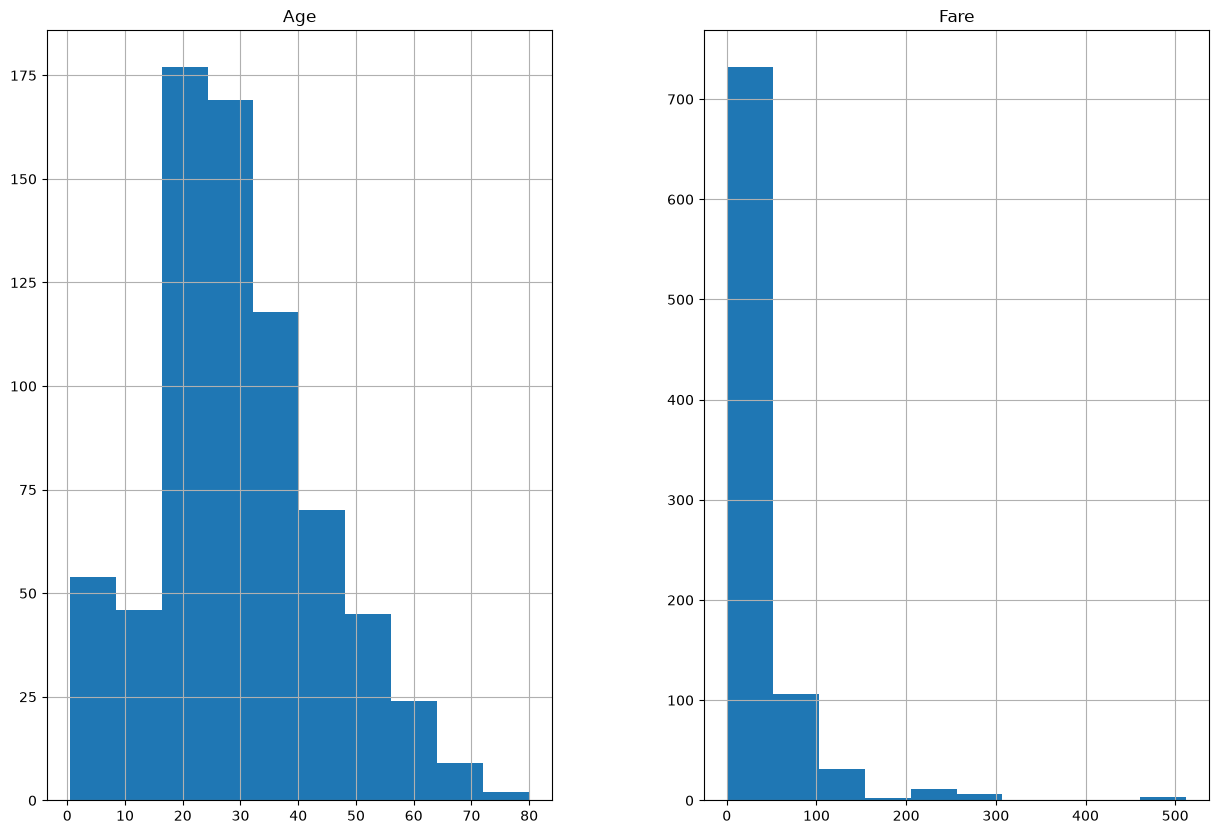

In [12]:
freqgraph.hist(figsize=(15,10))

In [15]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       2
dtype: int64

In [20]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [21]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

In [25]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name             int64
Sex              int64
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Embarked           str
dtype: object

In [28]:
df["Name"] = le.fit_transform(df["Name"])
df["Sex"] = le.fit_transform(df["Sex"])
df["Embarked"] = le.fit_transform(df["Embarked"])
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,108,1,22.0,1,0,A/5 21171,7.2500,2
1,2,1,1,190,0,38.0,1,0,PC 17599,71.2833,0
2,3,1,3,353,0,26.0,0,0,STON/O2. 3101282,7.9250,2
3,4,1,1,272,0,35.0,1,0,113803,53.1000,2
4,5,0,3,15,1,35.0,0,0,373450,8.0500,2
...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,548,1,27.0,0,0,211536,13.0000,2
887,888,1,1,303,0,19.0,0,0,112053,30.0000,2
888,889,0,3,413,0,28.0,1,2,W./C. 6607,23.4500,2
889,890,1,1,81,1,26.0,0,0,111369,30.0000,0


In [29]:
df.nunique()

PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Embarked         3
dtype: int64

In [33]:
df.drop(["PassengerId", "Name", "Ticket"], axis=1, inplace =True)
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.0,1,0,7.2500,2
1,1,1,0,38.0,1,0,71.2833,0
2,1,3,0,26.0,0,0,7.9250,2
3,1,1,0,35.0,1,0,53.1000,2
4,0,3,1,35.0,0,0,8.0500,2
...,...,...,...,...,...,...,...,...
886,0,2,1,27.0,0,0,13.0000,2
887,1,1,0,19.0,0,0,30.0000,2
888,0,3,0,28.0,1,2,23.4500,2
889,1,1,1,26.0,0,0,30.0000,0


In [50]:
from sklearn.preprocessing import MinMaxScaler
minmax = MinMaxScaler(feature_range=(0,2))

In [35]:
X = df.drop(["Survived"], axis = 1)
X

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,1,22.0,1,0,7.2500,2
1,1,0,38.0,1,0,71.2833,0
2,3,0,26.0,0,0,7.9250,2
3,1,0,35.0,1,0,53.1000,2
4,3,1,35.0,0,0,8.0500,2
...,...,...,...,...,...,...,...
886,2,1,27.0,0,0,13.0000,2
887,1,0,19.0,0,0,30.0000,2
888,3,0,28.0,1,2,23.4500,2
889,1,1,26.0,0,0,30.0000,0


In [37]:
Y =df["Survived"]
Y

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64

In [53]:
X1 = minmax.fit_transform(X)
X1 = pd.DataFrame(X1, columns = X.columns)
X1 = pd.concat([X1,Y], axis =1)
X1.describe()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,1.308642,1.295174,0.727358,0.130752,0.127198,0.125717,1.536476,0.383838
std,0.836071,0.955980,0.327210,0.275686,0.268686,0.193990,0.791503,0.486592
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.542347,0.000000,0.000000,0.030880,1.000000,0.000000
50%,2.000000,2.000000,0.693139,0.000000,0.000000,0.056425,2.000000,0.000000
75%,2.000000,2.000000,0.869063,0.250000,0.000000,0.121016,2.000000,1.000000
max,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000


In [54]:
X1

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,2.0,2.0,0.542347,0.25,0.000000,0.028302,2.0,0
1,0.0,0.0,0.944458,0.25,0.000000,0.278271,0.0,1
2,2.0,0.0,0.642875,0.00,0.000000,0.030937,2.0,1
3,0.0,0.0,0.869063,0.25,0.000000,0.207289,2.0,1
4,2.0,2.0,0.869063,0.00,0.000000,0.031425,2.0,0
...,...,...,...,...,...,...,...,...
886,1.0,2.0,0.668007,0.00,0.000000,0.050749,2.0,0
887,0.0,0.0,0.466951,0.00,0.000000,0.117112,2.0,1
888,2.0,0.0,0.693139,0.25,0.666667,0.091543,2.0,0
889,0.0,2.0,0.642875,0.00,0.000000,0.117112,0.0,1


In [56]:
X1.to_csv("titanic_dataset_cleaned.csv", index =False)